<a href="https://colab.research.google.com/github/NisalJayaweera/EN3160-Neural-Networks/blob/main/EN3160_Q2_MNIST_CNN_Comparison.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# EN3160 Assignment 3 — Question 2: MNIST CNN Comparison
**Task:** Compare LeNet-5 and a modern 3-convolution CNN with batch normalization and dropout over **10 epochs**, using identical data splits, optimizer, learning rate, batch size, and evaluation protocol. Plot train/test loss and accuracy and show a test confusion matrix for each model.

Run all cells in Google Colab. Enable GPU using **Runtime → Change runtime type → T4 GPU** if available. Report only results generated by execution.

In [1]:
import random, copy, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', device)
EPOCHS, BATCH_SIZE, LR = 10, 128, 1e-3


Device: cuda


## Dataset and shared experimental settings
MNIST contains 60,000 training and 10,000 test grayscale images of size 28×28. The same normalized dataset, batch size, Adam optimizer, cross-entropy loss and 10-epoch schedule are used for both architectures. Test metrics are computed after each epoch for assignment reporting; the test set is not used for training or hyperparameter selection.

In [2]:
transform = transforms.Compose([transforms.ToTensor(), transforms.Normalize((0.1307,), (0.3081,))])
train_ds = datasets.MNIST(root='./data', train=True, download=True, transform=transform)
test_ds = datasets.MNIST(root='./data', train=False, download=True, transform=transform)
# Separate identically seeded shuffle generators so both models see the same epoch order.
def make_train_loader():
    gen = torch.Generator().manual_seed(SEED)
    return DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, generator=gen, num_workers=2, pin_memory=torch.cuda.is_available())
test_loader = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=torch.cuda.is_available())
print(len(train_ds), 'training images;', len(test_ds), 'test images')


100%|██████████| 9.91M/9.91M [00:00<00:00, 14.1MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 339kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 3.18MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 11.2MB/s]

60000 training images; 10000 test images


## Architectures
**LeNet-5 adaptation:** two tanh convolutions, average pooling, then 120→84→10 fully connected classifier; the original LeNet-5 used a different input size/output treatment, so this is a standard MNIST-adapted version.

**Modern CNN:** exactly three convolution layers, each followed by batch normalization and ReLU; max pooling after the first two convolutions, dropout, and a linear classifier.

In [3]:
class LeNet5(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 6, kernel_size=5, padding=2), nn.Tanh(),
            nn.AvgPool2d(2),
            nn.Conv2d(6, 16, kernel_size=5), nn.Tanh(),
            nn.AvgPool2d(2),
        )
        self.classifier = nn.Sequential(nn.Flatten(), nn.Linear(16*5*5, 120), nn.Tanh(), nn.Linear(120, 84), nn.Tanh(), nn.Linear(84, 10))
    def forward(self, x): return self.classifier(self.features(x))

class ModernCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 32, 3, padding=1), nn.BatchNorm2d(32), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, padding=1), nn.BatchNorm2d(64), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(64, 128, 3, padding=1), nn.BatchNorm2d(128), nn.ReLU(),
            nn.AdaptiveAvgPool2d((1,1)),
        )
        self.classifier = nn.Sequential(nn.Flatten(), nn.Dropout(0.3), nn.Linear(128, 10))
    def forward(self, x): return self.classifier(self.features(x))

for cls in [LeNet5, ModernCNN]:
    m = cls()
    print(cls.__name__, 'parameters:', sum(p.numel() for p in m.parameters()))
    print('Output shape:', tuple(m(torch.zeros(2,1,28,28)).shape))


LeNet5 parameters: 61706
Output shape: (2, 10)
ModernCNN parameters: 94410
Output shape: (2, 10)


## Training and evaluation
Training loss and accuracy are accumulated over minibatches during the training pass. Evaluation metrics are computed with `model.eval()` to ensure dropout is disabled and batch normalization uses running statistics. All reported losses are mean cross-entropy per example.

In [4]:
criterion = nn.CrossEntropyLoss()
def evaluate(model, loader, return_predictions=False):
    model.eval()
    total_loss = correct = total = 0
    all_true, all_pred = [], []
    with torch.no_grad():
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            logits = model(x)
            total_loss += criterion(logits, y).item() * y.size(0)
            pred = logits.argmax(dim=1)
            correct += (pred == y).sum().item()
            total += y.size(0)
            if return_predictions:
                all_true.extend(y.cpu().tolist()); all_pred.extend(pred.cpu().tolist())
    if return_predictions: return total_loss/total, 100*correct/total, all_true, all_pred
    return total_loss/total, 100*correct/total

def train_model(model, name):
    torch.manual_seed(SEED)
    model = model.to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=LR)
    loader = make_train_loader()
    history = []
    for epoch in range(1, EPOCHS+1):
        model.train()
        train_loss_sum = train_correct = count = 0
        start = time.time()
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            optimizer.zero_grad(set_to_none=True)
            logits = model(x)
            loss = criterion(logits, y)
            loss.backward(); optimizer.step()
            train_loss_sum += loss.item()*y.size(0)
            train_correct += (logits.argmax(1) == y).sum().item()
            count += y.size(0)
        test_loss, test_acc = evaluate(model, test_loader)
        entry = dict(model=name, epoch=epoch, train_loss=train_loss_sum/count,
                     train_accuracy=100*train_correct/count, test_loss=test_loss, test_accuracy=test_acc)
        history.append(entry)
        print(f'{name} | Epoch {epoch:02d}/{EPOCHS} | train acc {entry["train_accuracy"]:.2f}% | test acc {test_acc:.2f}% | train loss {entry["train_loss"]:.4f} | test loss {test_loss:.4f} | {time.time()-start:.1f}s')
    return model, pd.DataFrame(history)


In [5]:
lenet, lenet_history = train_model(LeNet5(), 'LeNet-5')
modern, modern_history = train_model(ModernCNN(), 'Modern CNN')
history = pd.concat([lenet_history, modern_history], ignore_index=True)


LeNet-5 | Epoch 01/10 | train acc 90.62% | test acc 96.67% | train loss 0.3391 | test loss 0.1131 | 15.5s
LeNet-5 | Epoch 02/10 | train acc 97.31% | test acc 97.88% | train loss 0.0893 | test loss 0.0685 | 13.0s
LeNet-5 | Epoch 03/10 | train acc 98.25% | test acc 98.28% | train loss 0.0579 | test loss 0.0565 | 12.9s
LeNet-5 | Epoch 04/10 | train acc 98.66% | test acc 98.31% | train loss 0.0448 | test loss 0.0516 | 13.2s
LeNet-5 | Epoch 05/10 | train acc 98.94% | test acc 98.48% | train loss 0.0349 | test loss 0.0452 | 14.6s
LeNet-5 | Epoch 06/10 | train acc 99.11% | test acc 98.70% | train loss 0.0281 | test loss 0.0428 | 13.2s
LeNet-5 | Epoch 07/10 | train acc 99.26% | test acc 98.42% | train loss 0.0237 | test loss 0.0492 | 13.3s
LeNet-5 | Epoch 08/10 | train acc 99.35% | test acc 98.55% | train loss 0.0208 | test loss 0.0447 | 13.4s
LeNet-5 | Epoch 09/10 | train acc 99.50% | test acc 98.66% | train loss 0.0160 | test loss 0.0427 | 13.3s
LeNet-5 | Epoch 10/10 | train acc 99.53% | tes

## Per-epoch training and test curves

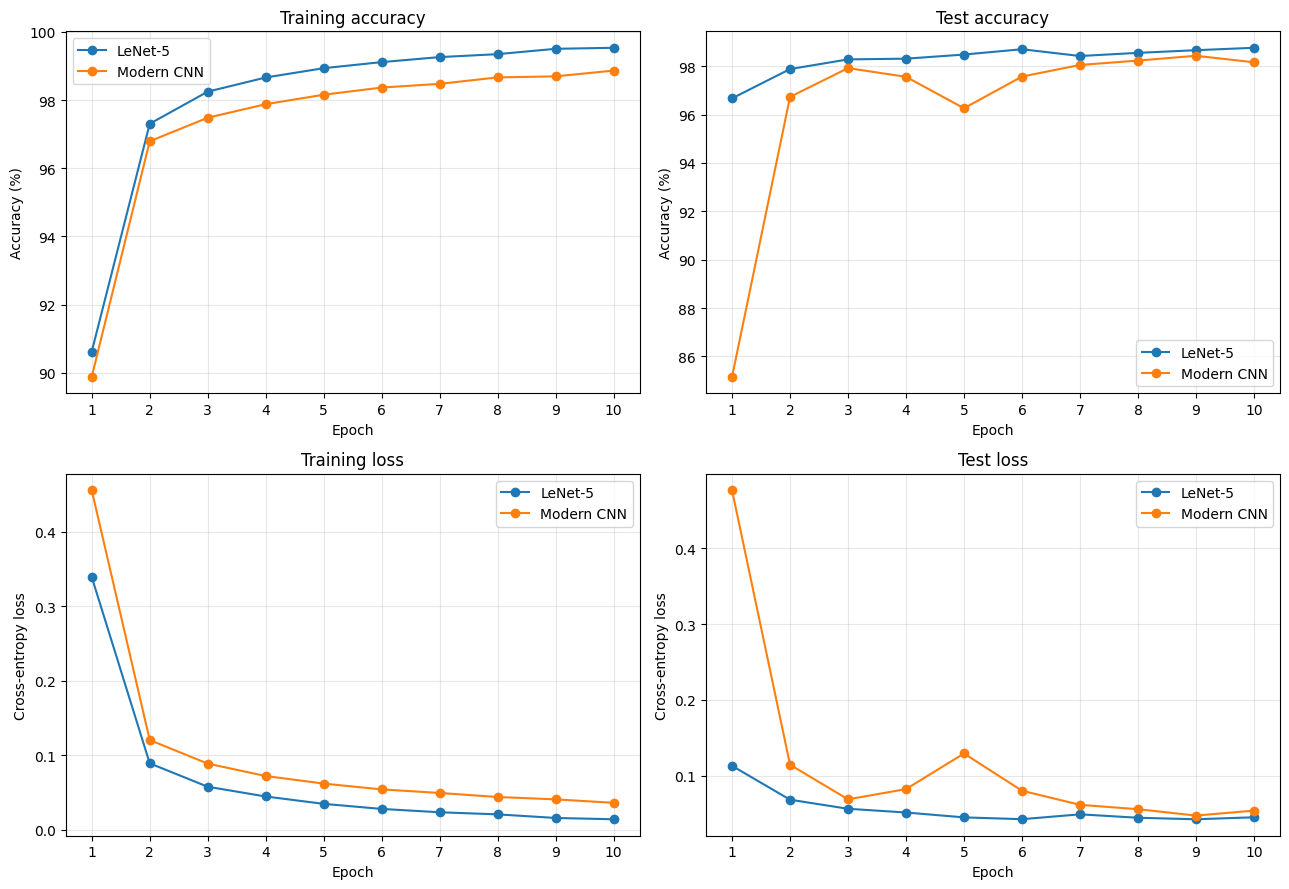

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
for name, group in history.groupby('model', sort=False):
    for ax, key in zip(axes.flat, ['train_accuracy', 'test_accuracy', 'train_loss', 'test_loss']):
        ax.plot(group.epoch, group[key], marker='o', label=name)
for ax, title, ylabel in zip(axes.flat,
    ['Training accuracy', 'Test accuracy', 'Training loss', 'Test loss'],
    ['Accuracy (%)', 'Accuracy (%)', 'Cross-entropy loss', 'Cross-entropy loss']):
    ax.set(title=title, xlabel='Epoch', ylabel=ylabel)
    ax.set_xticks(range(1, EPOCHS+1)); ax.grid(alpha=.3); ax.legend()
fig.tight_layout(); plt.show()


## Confusion matrices on the complete 10,000-image test set

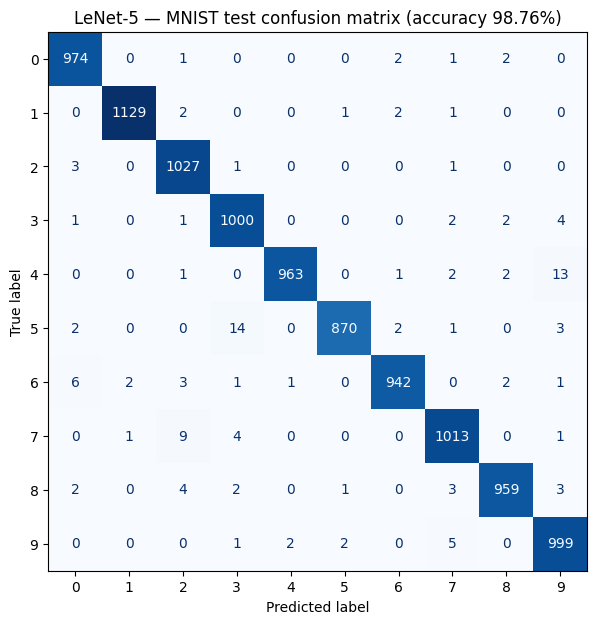

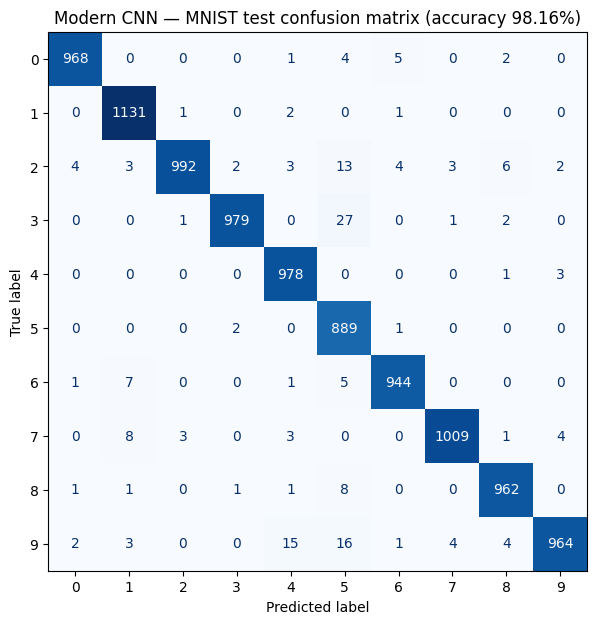

In [7]:
for name, model in [('LeNet-5', lenet), ('Modern CNN', modern)]:
    loss, acc, truth, predicted = evaluate(model, test_loader, return_predictions=True)
    cm = confusion_matrix(truth, predicted, labels=list(range(10)))
    disp = ConfusionMatrixDisplay(cm, display_labels=list(range(10)))
    fig, ax = plt.subplots(figsize=(8, 7))
    disp.plot(ax=ax, cmap='Blues', values_format='d', colorbar=False)
    ax.set_title(f'{name} — MNIST test confusion matrix (accuracy {acc:.2f}%)')
    plt.show()


## Results table and interpretation
The table below is generated from the actual training history. Discuss which model achieved higher test accuracy, whether the training/test gap suggests overfitting, and which digit pairs are most frequently confused. Avoid claiming a model is better before checking the measured results.

In [8]:
summary = history[history.epoch == EPOCHS][['model', 'train_accuracy', 'test_accuracy', 'train_loss', 'test_loss']].copy()
print(summary.to_string(index=False, float_format=lambda v: f'{v:.4f}'))
from pathlib import Path
out = Path('results/q2'); out.mkdir(parents=True, exist_ok=True)
history.to_csv(out/'mnist_cnn_history.csv', index=False)
summary.to_csv(out/'mnist_cnn_summary.csv', index=False)
print('Saved:', out.resolve())


     model  train_accuracy  test_accuracy  train_loss  test_loss
   LeNet-5         99.5350        98.7600      0.0143     0.0453
Modern CNN         98.8667        98.1600      0.0363     0.0541
Saved: /content/results/q2


### Discussion template (complete after running)
Both models were trained for 10 epochs on MNIST using identical preprocessing, minibatch size, optimizer, and learning rate. LeNet-5 achieved **[insert measured test accuracy]**, while the modern CNN achieved **[insert measured test accuracy]**. The model with the higher test accuracy was **[name]**. The train–test accuracy gaps were **[values]**, indicating **[interpretation]**. Inspection of the confusion matrices shows that **[digit pairs]** were most often confused. Batch normalization and dropout are architectural differences that may affect optimization and generalization; the experiment alone does not isolate their individual effects.